# 01 — Nạp dữ liệu, làm sạch và EDA nguồn

**Câu hỏi:** Dữ liệu có đáng tin, thiếu ở đâu và cần chuẩn hóa như thế nào?

Chọn kernel .venv, sau đó Restart Kernel → Run All.
Đường dẫn tương đối hỗ trợ project root và work/pipeline/.
Đầu vào: CSV raw. Đầu ra: processed parquet, QA, dictionary và manifest PASS.
Notebook 02–03 cần manifest để xác nhận dữ liệu đã xử lý; không dùng biến của kernel này.

## 1. Import thư viện

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

## 2. Kiểm tra đường dẫn
Bảng dưới xác nhận vị trí nguồn và các đầu ra.

In [3]:
# Tìm project bằng đường dẫn tương đối từ thư mục làm việc.
root_candidates = [Path("."), *[Path("../" * level) for level in range(1, 7)]]
project_root = next(
    (path for path in root_candidates
     if (path / "data" / "cell2celltrain.csv").is_file()
     and (path / "work" / "pipeline").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Mở notebook từ project root hoặc work/pipeline; "
        "cần data/cell2celltrain.csv và work/pipeline/."
    )

source_path = project_root / "data" / "cell2celltrain.csv"
build_dir = project_root / "work" / "build"
processed_path = build_dir / "processed_customers.parquet"
qa_path = build_dir / "qa_report.json"
manifest_path = build_dir / "preparation_manifest.json"
display(pd.DataFrame({
    "Thành phần": ["Nguồn raw", "Processed", "Manifest"],
    "Đường dẫn tương đối": [str(source_path), str(processed_path), str(manifest_path)],
    "Tồn tại": [source_path.is_file(), processed_path.is_file(), manifest_path.is_file()],
}))

,Thành phần,Đường dẫn tương đối,Tồn tại
0,Nguồn raw,..\..\data\cell2celltrain.csv,True
1,Processed,..\..\work\build\processed_customers.parquet,True
2,Manifest,..\..\work\build\preparation_manifest.json,True


In [4]:
pd.set_option("display.max_columns", 15)
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 10})
SOURCE_SHA256 = hashlib.sha256(source_path.read_bytes()).hexdigest()
print("SHA256 nguồn:", SOURCE_SHA256)
display(pd.Series({
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "matplotlib", "pyarrow"]
}).to_frame("Version"))

SHA256 nguồn: 3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6cbb64f4c8990f9a645


,Version
numpy,2.2.6
pandas,3.0.2
matplotlib,3.10.7
pyarrow,26.0.0


## 3. Nạp raw và xem cấu trúc
Chuỗi NA/N/A/?/NULL được nhận diện missing khi đọc. Chưa thay đổi feature.

In [5]:
raw = pd.read_csv(
    source_path, na_values=["NA", "N/A", "?", "NULL"], low_memory=False,
)
print(f"Nguồn: {raw.shape[0]:,} dòng × {raw.shape[1]} cột")
# Không lưu CustomerID của từng khách trong output notebook.
display(raw.drop(columns=["CustomerID"], errors="ignore").head())
display(raw.dtypes.value_counts().to_frame("Số cột"))

Nguồn: 51,047 dòng × 58 cột


,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,...,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,Yes,24.00,219.0,22.0,0.25,0.0,0.0,...,0,30,Yes,1-Highest,Suburban,Professional,No
1,Yes,16.99,10.0,17.0,0.00,0.0,0.0,...,0,30,No,4-Medium,Suburban,Professional,Yes
2,No,38.00,8.0,38.0,0.00,0.0,0.0,...,0,Unknown,No,3-Good,Town,Crafts,Yes
3,No,82.28,1312.0,75.0,1.24,0.0,0.0,...,0,10,No,4-Medium,Other,Other,No
4,Yes,17.14,0.0,17.0,0.00,0.0,0.0,...,1,10,No,1-Highest,Other,Professional,Yes


,Số cột
float64,26
str,23
int64,9


In [6]:
FEATURES = [
    "MonthsInService", "CurrentEquipmentDays", "HandsetWebCapable",
    "MonthlyRevenue", "TotalRecurringCharge", "CreditRating",
    "MonthlyMinutes", "PercChangeMinutes", "PercChangeRevenues", "PeakCallsInOut",
]
CATEGORICAL = ["HandsetWebCapable", "CreditRating"]
NUMERIC = [column for column in FEATURES if column not in CATEGORICAL]
BAND_COLUMNS = [
    "TenureBand", "EquipmentAgeBand", "ValueTier", "ChargeBand",
    "MinutesBand", "UsageTrendBand", "RevenueTrendBand",
]

### Kiểm tra hợp đồng nguồn
Dừng có thông báo rõ nếu thiếu cột, ID lỗi hoặc target khác Yes/No.

In [7]:
required_columns = ["CustomerID", "Churn", *FEATURES]
absent = sorted(set(required_columns) - set(raw.columns))
if absent:
    raise ValueError(f"Thiếu cột bắt buộc: {absent}")
raw_ids = raw.CustomerID.astype("string").str.strip()
target = raw.Churn.astype("string").str.strip()
source_checks = pd.Series({
    "Nguồn có dữ liệu": len(raw) > 0,
    "ID không NA/rỗng": raw_ids.notna().all() and raw_ids.fillna("").ne("").all(),
    "ID duy nhất": raw_ids.is_unique,
    "Target chỉ Yes/No": target.isin(["Yes", "No"]).all(),
    "Có cả hai lớp": set(target.dropna()) == {"Yes", "No"},
}, name="PASS")
display(source_checks.to_frame())
if not source_checks.all():
    raise ValueError("Nguồn vi phạm hợp đồng; xem bảng kiểm tra ở trên.")

,PASS
Nguồn có dữ liệu,True
ID không NA/rỗng,True
ID duy nhất,True
Target chỉ Yes/No,True
Có cả hai lớp,True


## 4. EDA raw — phân bố target
Xem mức mất cân bằng trước khi chọn metric mô hình.

,Customers,Share
Churn,,
No,36336,0.711815
Yes,14711,0.288185


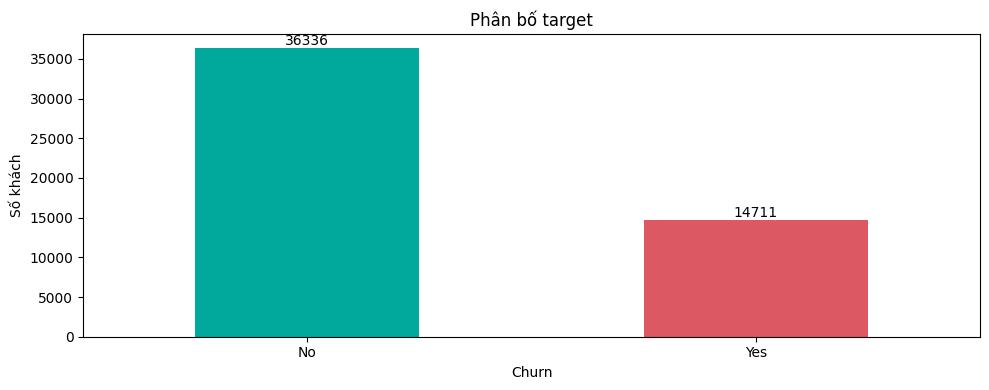

**Nhận xét:** churn chiếm **28.82%**. Cần đánh giá ranking/precision–recall; accuracy riêng lẻ chưa đủ.

In [8]:
target_table = target.value_counts().reindex(["No", "Yes"]).to_frame("Customers")
target_table["Share"] = target_table.Customers / len(raw)
display(target_table)
fig, ax = plt.subplots()
target_table.Customers.plot.bar(ax=ax, color=["#00a99b", "#dc5964"], rot=0)
ax.set(title="Phân bố target", xlabel="Churn", ylabel="Số khách")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Nhận xét:** churn chiếm **{target.eq('Yes').mean():.2%}**. "
    "Cần đánh giá ranking/precision–recall; accuracy riêng lẻ chưa đủ."
))

### Missing trên toàn bộ nguồn
Bảng/biểu đồ chỉ hiển thị cột có missing.

,Missing,MissingRate
AgeHH1,909,0.017807
AgeHH2,909,0.017807
PercChangeRevenues,367,0.007189
PercChangeMinutes,367,0.007189
DirectorAssistedCalls,156,0.003056
TotalRecurringCharge,156,0.003056
RoamingCalls,156,0.003056
OverageMinutes,156,0.003056
MonthlyRevenue,156,0.003056
MonthlyMinutes,156,0.003056


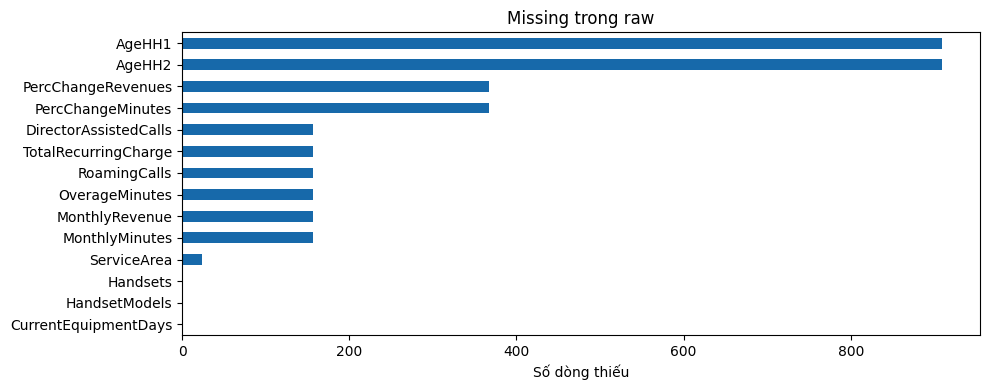

In [9]:
raw_missing = pd.DataFrame({
    "Missing": raw.isna().sum(), "MissingRate": raw.isna().mean(),
}).sort_values("Missing", ascending=False)
display(raw_missing.query("Missing > 0"))
fig, ax = plt.subplots()
raw_missing.query("Missing > 0").Missing.plot.barh(ax=ax, color="#1769aa")
ax.invert_yaxis()
ax.set(title="Missing trong raw", xlabel="Số dòng thiếu", ylabel="")
plt.tight_layout()
plt.show()

## 5. Chuẩn hóa target và predictor
Tạo bản sao; numeric lỗi thành NaN có thống kê riêng; categorical thiếu/rỗng thành Unknown.

In [10]:
clean = raw[required_columns].copy()
clean["CustomerID"] = raw_ids
clean["Churn"] = target.eq("Yes").astype("int8")
conversion_errors = {}
for column in NUMERIC:
    converted = pd.to_numeric(clean[column], errors="coerce")
    conversion_errors[column] = int((clean[column].notna() & converted.isna()).sum())
    clean[column] = converted
for column in CATEGORICAL:
    clean[column] = (
        clean[column].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
    )
display(pd.Series(conversion_errors, name="Lỗi định dạng mới").to_frame())
display(clean.drop(columns="CustomerID").head())

,Lỗi định dạng mới
MonthsInService,0
CurrentEquipmentDays,0
MonthlyRevenue,0
TotalRecurringCharge,0
MonthlyMinutes,0
PercChangeMinutes,0
PercChangeRevenues,0
PeakCallsInOut,0


,Churn,MonthsInService,CurrentEquipmentDays,HandsetWebCapable,MonthlyRevenue,TotalRecurringCharge,CreditRating,MonthlyMinutes,PercChangeMinutes,PercChangeRevenues,PeakCallsInOut
0,1,61,361.0,Yes,24.00,22.0,1-Highest,219.0,-157.0,-19.0,58.0
1,1,58,1504.0,No,16.99,17.0,4-Medium,10.0,-4.0,0.0,5.0
2,0,60,1812.0,No,38.00,38.0,3-Good,8.0,-2.0,0.0,1.3
3,0,59,458.0,Yes,82.28,75.0,4-Medium,1312.0,157.0,8.1,555.7
4,1,53,852.0,No,17.14,17.0,1-Highest,0.0,0.0,-0.2,0.0


### Kiểm tra sau chuẩn hóa
Đối soát ID, thứ tự, target, dtype và infinity; không chỉ đếm số dòng.

In [11]:
normalization_checks = pd.Series({
    "Không mất dòng": len(clean) == len(raw),
    "ID và thứ tự giữ nguyên": clean.CustomerID.equals(raw_ids),
    "Target mã hóa đúng": clean.Churn.eq(target.eq("Yes").astype("int8")).all(),
    "Numeric đúng kiểu": all(pd.api.types.is_numeric_dtype(clean[c]) for c in NUMERIC),
    "Không infinity": not np.isinf(clean[NUMERIC].to_numpy(dtype=float)).any(),
    "Categorical có nhãn": not clean[CATEGORICAL].isna().any().any(),
}, name="PASS")
display(normalization_checks.to_frame())
if not normalization_checks.all():
    raise ValueError("Chuẩn hóa không đối soát.")

,PASS
Không mất dòng,True
ID và thứ tự giữ nguyên,True
Target mã hóa đúng,True
Numeric đúng kiểu,True
Không infinity,True
Categorical có nhãn,True


## 6. EDA sau chuẩn hóa — phân bố numeric
Giữ outlier để quan sát; chưa có quy tắc nghiệp vụ để loại bỏ.

,count,mean,std,min,25%,50%,75%,max
MonthsInService,51047.0,18.756264,9.800138,6.00,11.00,16.00,24.000,61.00
CurrentEquipmentDays,51046.0,380.545841,253.801982,-5.00,205.00,329.00,515.000,1812.00
MonthlyRevenue,50891.0,58.834492,44.507336,-6.17,33.61,48.46,71.065,1223.38
TotalRecurringCharge,50891.0,46.830088,23.848871,-11.00,30.00,45.00,60.000,400.00
MonthlyMinutes,50891.0,525.653416,529.871063,0.00,158.00,366.00,723.000,7359.00
PercChangeMinutes,50680.0,-11.547908,257.514772,-3875.00,-83.00,-5.00,66.000,5192.00
PercChangeRevenues,50680.0,-1.191985,39.574915,-1107.70,-7.10,-0.30,1.600,2483.50
PeakCallsInOut,51047.0,90.549515,104.947470,0.00,23.00,62.00,121.300,2090.70


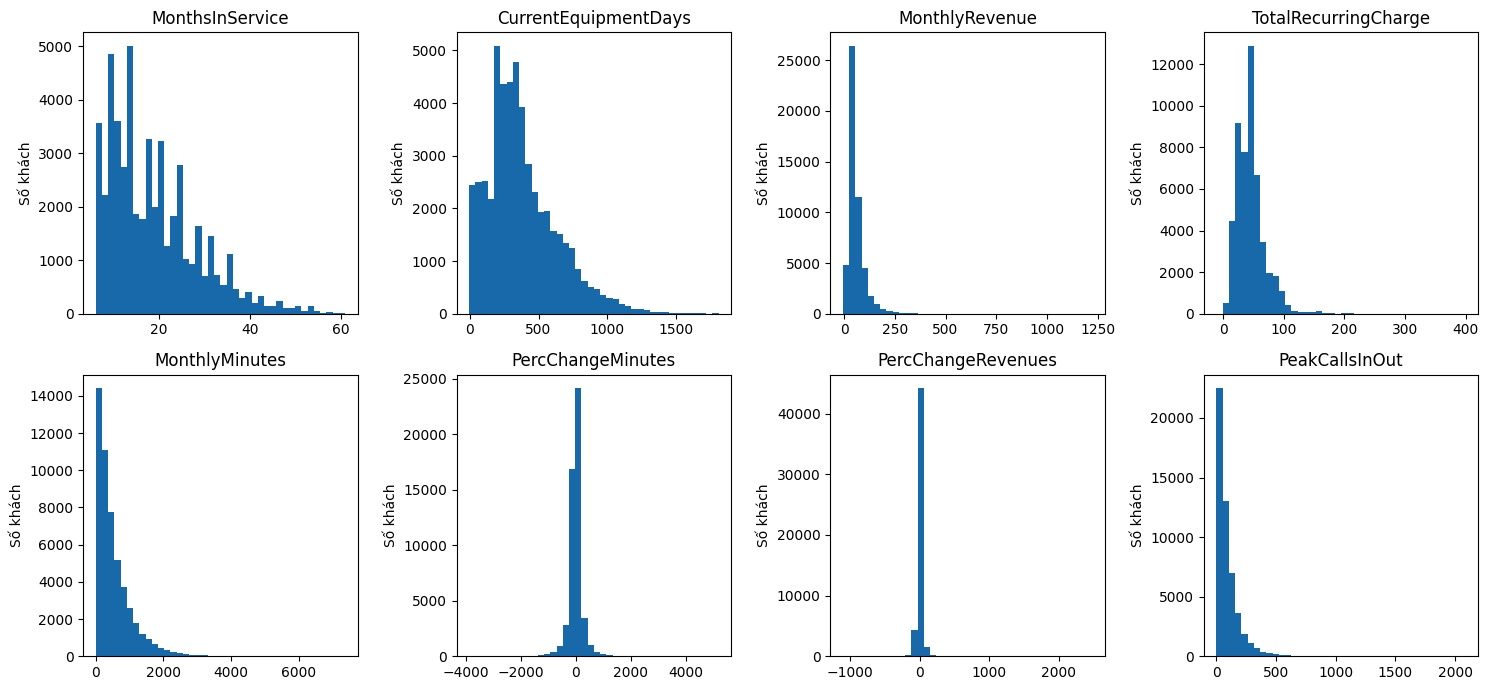

,Median,P95,Maximum,Skewness
MonthsInService,16.00,37.00,61.00,1.056937
CurrentEquipmentDays,329.00,866.00,1812.00,1.086106
MonthlyRevenue,48.46,135.18,1223.38,4.181761
TotalRecurringCharge,45.00,85.00,400.00,1.629344
MonthlyMinutes,366.00,1576.50,7359.00,2.193967
PercChangeMinutes,-5.00,345.00,5192.00,-0.324255
PercChangeRevenues,-0.30,46.50,2483.50,7.885302
PeakCallsInOut,62.00,279.70,2090.70,3.327854


**Nhận xét phân bố:** các biến có |skewness| > 1: MonthsInService, CurrentEquipmentDays, MonthlyRevenue, TotalRecurringCharge, MonthlyMinutes, PercChangeRevenues, PeakCallsInOut. Đọc median/P95 cùng maximum để thấy đuôi phân bố; giá trị xa trung tâm cần được kiểm tra nghiệp vụ trước khi loại.

In [12]:
display(clean[NUMERIC].describe().T)
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for column, ax in zip(NUMERIC, axes.flat):
    ax.hist(clean[column].dropna(), bins=40, color="#1769aa")
    ax.set(title=column, ylabel="Số khách")
plt.tight_layout()
plt.show()

distribution_summary = pd.DataFrame({
    "Median": clean[NUMERIC].median(),
    "P95": clean[NUMERIC].quantile(0.95),
    "Maximum": clean[NUMERIC].max(),
    "Skewness": clean[NUMERIC].skew(),
})
display(distribution_summary)
skewed = distribution_summary.index[distribution_summary.Skewness.abs().gt(1)].tolist()
display(Markdown(
    "**Nhận xét phân bố:** các biến có |skewness| > 1: "
    + (", ".join(skewed) if skewed else "không có")
    + ". Đọc median/P95 cùng maximum để thấy đuôi phân bố; "
      "giá trị xa trung tâm cần được kiểm tra nghiệp vụ trước khi loại."
))

### Missing theo predictor và cohort
Xem việc loại missing sẽ mất bao nhiêu khách/churner.

In [13]:
missing_by_feature = (
    {c: int(clean[c].isna().sum()) for c in NUMERIC}
    | {c: int(clean[c].eq("Unknown").sum()) for c in CATEGORICAL}
)
missing_any = (
    clean[NUMERIC].isna().any(axis=1)
    | clean[CATEGORICAL].eq("Unknown").any(axis=1)
)
display(pd.Series(missing_by_feature, name="Missing").sort_values(ascending=False).to_frame())
display(clean.assign(MissingPredictor=missing_any).groupby("MissingPredictor").agg(
    Customers=("Churn", "size"), Churners=("Churn", "sum"), ChurnRate=("Churn", "mean"),
))
display(Markdown(
    f"**Quyết định:** giữ {int(missing_any.sum()):,} khách thiếu predictor "
    f"(gồm {int(clean.loc[missing_any, 'Churn'].sum()):,} churner). "
    "CatBoost xử lý numeric NaN; categorical đã có nhãn Unknown."
))

,Missing
PercChangeRevenues,367
PercChangeMinutes,367
MonthlyMinutes,156
MonthlyRevenue,156
TotalRecurringCharge,156
CurrentEquipmentDays,1
MonthsInService,0
PeakCallsInOut,0
HandsetWebCapable,0
CreditRating,0


,Customers,Churners,ChurnRate
MissingPredictor,,,
False,50679,14503,0.286174
True,368,208,0.565217


**Quyết định:** giữ 368 khách thiếu predictor (gồm 208 churner). CatBoost xử lý numeric NaN; categorical đã có nhãn Unknown.

### Giá trị âm và categorical
Âm của PercChange có thể thể hiện mức giảm; âm tuổi thiết bị/phí cần gắn cờ.

In [14]:
negative_counts = {c: int(clean[c].lt(0).sum()) for c in NUMERIC}
display(pd.Series(negative_counts, name="Giá trị âm").to_frame())
for column in CATEGORICAL:
    display(clean[column].value_counts(dropna=False).rename_axis(column).to_frame("Customers"))

,Giá trị âm
MonthsInService,0
CurrentEquipmentDays,76
MonthlyRevenue,3
TotalRecurringCharge,8
MonthlyMinutes,0
PercChangeMinutes,26816
PercChangeRevenues,28408
PeakCallsInOut,0


,Customers
HandsetWebCapable,
Yes,46046
No,5001


,Customers
CreditRating,
2-High,18993
1-Highest,8522
3-Good,8410
5-Low,6499
4-Medium,5357
7-Lowest,2114
6-VeryLow,1152


### Kết luận EDA nguồn

Giữ raw và mọi dòng có ID/target hợp lệ; không cắt outlier tùy ý.
Missing và giá trị âm được ghi nhận để người đọc thấy ảnh hưởng tới mẫu số.
PercChange chưa rõ đơn vị/timing; snapshot không chứng minh nhân quả.

## 7. Tạo band phân tích
Công khai ngưỡng; pd.cut đóng bên phải. Missing/âm có nhãn riêng.

In [15]:
band_specs = {
    "TenureBand": ("MonthsInService", [-np.inf, 11, 18, 24, np.inf],
                   ["6–11 tháng", "12–18 tháng", "19–24 tháng", "25+ tháng"]),
    "EquipmentAgeBand": ("CurrentEquipmentDays", [0, 180, 365, 730, np.inf],
                         ["≤180 ngày", "181–365 ngày", "366–730 ngày", ">730 ngày"]),
    "ValueTier": ("MonthlyRevenue", [0, 35, 70, np.inf],
                  ["Thấp (≤35)", "Trung bình (35–70)", "Cao (>70)"]),
    "ChargeBand": ("TotalRecurringCharge", [0, 30, 60, np.inf], ["≤30", "30–60", ">60"]),
    "MinutesBand": ("MonthlyMinutes", [-np.inf, 150, 500, np.inf], ["≤150", "151–500", ">500"]),
    "UsageTrendBand": ("PercChangeMinutes", [-np.inf, -83, 0, 66, np.inf],
                       ["Giảm mạnh (≤-83)", "Giảm nhẹ (-83–0)", "Tăng nhẹ (0–66)", "Tăng mạnh (>66)"]),
    "RevenueTrendBand": ("PercChangeRevenues", [-np.inf, -7.1, 0, 1.6, np.inf],
                         ["Giảm mạnh (≤-7,1)", "Giảm nhẹ (-7,1–0)", "Tăng nhẹ (0–1,6)", "Tăng mạnh (>1,6)"]),
}
if not clean.MonthsInService.dropna().ge(6).all():
    raise ValueError("Nguồn có tenure <6; cần sửa nhãn tenure cho đúng.")
if not clean.MonthlyMinutes.dropna().mod(1).eq(0).all():
    raise ValueError("Minutes không nguyên; cần sửa nhãn 151–500.")
display(pd.DataFrame([
    {"Band": band, "Source": spec[0], "Bins": str(spec[1]), "Labels": str(spec[2])}
    for band, spec in band_specs.items()
]))

,Band,Source,Bins,Labels
0,TenureBand,MonthsInService,"[-inf, 11, 18, 24, inf]","['6–11 tháng', '12–18 tháng', '19–24 tháng', '..."
1,EquipmentAgeBand,CurrentEquipmentDays,"[0, 180, 365, 730, inf]","['≤180 ngày', '181–365 ngày', '366–730 ngày', ..."
2,ValueTier,MonthlyRevenue,"[0, 35, 70, inf]","['Thấp (≤35)', 'Trung bình (35–70)', 'Cao (>70)']"
3,ChargeBand,TotalRecurringCharge,"[0, 30, 60, inf]","['≤30', '30–60', '>60']"
4,MinutesBand,MonthlyMinutes,"[-inf, 150, 500, inf]","['≤150', '151–500', '>500']"
5,UsageTrendBand,PercChangeMinutes,"[-inf, -83, 0, 66, inf]","['Giảm mạnh (≤-83)', 'Giảm nhẹ (-83–0)', 'Tăng..."
6,RevenueTrendBand,PercChangeRevenues,"[-inf, -7.1, 0, 1.6, inf]","['Giảm mạnh (≤-7,1)', 'Giảm nhẹ (-7,1–0)', 'Tă..."


In [16]:
processed = clean.copy()
for band, (column, bins, labels) in band_specs.items():
    processed[band] = pd.cut(
        processed[column], bins=bins, labels=labels, include_lowest=True,
    ).astype("string").fillna("Không rõ")
for band, column in [
    ("EquipmentAgeBand", "CurrentEquipmentDays"),
    ("ValueTier", "MonthlyRevenue"), ("ChargeBand", "TotalRecurringCharge"),
]:
    processed.loc[processed[column].lt(0), band] = "Giá trị âm"

band_checks = pd.Series({
    "Không mất dòng": len(processed) == len(clean),
    "Feature gốc giữ nguyên": processed[required_columns].equals(clean),
    "Band có nhãn cho mọi dòng": not processed[BAND_COLUMNS].isna().any().any(),
    "Missing usage khớp": processed.UsageTrendBand.eq("Không rõ").sum() == clean.PercChangeMinutes.isna().sum(),
}, name="PASS")
display(band_checks.to_frame())
display(processed[BAND_COLUMNS].head())
if not band_checks.all():
    raise ValueError("Band không bảo toàn dữ liệu.")

,PASS
Không mất dòng,True
Feature gốc giữ nguyên,True
Band có nhãn cho mọi dòng,True
Missing usage khớp,True


,TenureBand,EquipmentAgeBand,ValueTier,ChargeBand,MinutesBand,UsageTrendBand,RevenueTrendBand
0,25+ tháng,181–365 ngày,Thấp (≤35),≤30,151–500,Giảm mạnh (≤-83),"Giảm mạnh (≤-7,1)"
1,25+ tháng,>730 ngày,Thấp (≤35),≤30,≤150,Giảm nhẹ (-83–0),"Giảm nhẹ (-7,1–0)"
2,25+ tháng,>730 ngày,Trung bình (35–70),30–60,≤150,Giảm nhẹ (-83–0),"Giảm nhẹ (-7,1–0)"
3,25+ tháng,366–730 ngày,Cao (>70),>60,>500,Tăng mạnh (>66),"Tăng mạnh (>1,6)"
4,25+ tháng,>730 ngày,Thấp (≤35),≤30,≤150,Giảm nhẹ (-83–0),"Giảm nhẹ (-7,1–0)"


## 8. Xuất processed và QA
Manifest chỉ PASS sau khi đọc lại parquet và đối soát toàn bảng.

In [17]:
build_dir.mkdir(exist_ok=True)
qa = {
    "source": "data/cell2celltrain.csv", "source_sha256": SOURCE_SHA256,
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "raw_rows": len(raw), "raw_columns": len(raw.columns),
    "unique_customer_ids": int(processed.CustomerID.nunique()),
    "target_counts": {"Yes": int(processed.Churn.sum()), "No": int(processed.Churn.eq(0).sum())},
    "baseline_churn_rate": float(processed.Churn.mean()),
    "missing_by_feature": missing_by_feature,
    "missing_any_model_feature_rows": int(missing_any.sum()),
    "missing_any_model_feature_churners": int(processed.loc[missing_any, "Churn"].sum()),
    "complete_10_feature_rows": int((~missing_any).sum()),
    "complete_58_column_rows": int(raw.notna().all(axis=1).sum()),
    "negative_numeric_counts": negative_counts, "numeric_conversion_errors": conversion_errors,
    "invalid_target_rows": 0, "missing_id_rows": 0, "duplicate_id_rows": 0,
    "notes": ["Negative values retained.", "PercChange units/timing unverified."],
}
processed.to_parquet(processed_path, index=False)
qa_path.write_text(json.dumps(qa, ensure_ascii=False, indent=2), encoding="utf-8")
dictionary = pd.DataFrame([
    {"Column": column, "Dtype": str(processed[column].dtype),
     "Missing": int(processed[column].isna().sum()),
     "Role": "ID" if column == "CustomerID" else "Target" if column == "Churn"
             else "Predictor" if column in FEATURES else "Analysis band"}
    for column in processed.columns
])
dictionary.to_csv(build_dir / "data_dictionary.csv", index=False, encoding="utf-8-sig")

In [18]:
reloaded = pd.read_parquet(processed_path)
pd.testing.assert_frame_equal(processed, reloaded)
manifest = {
    "schema_version": 1, "status": "passed",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_sha256": SOURCE_SHA256,
    "processed_sha256": hashlib.sha256(processed_path.read_bytes()).hexdigest(),
    "qa_sha256": hashlib.sha256(qa_path.read_bytes()).hexdigest(),
    "rows": len(reloaded), "columns": reloaded.columns.tolist(), "features": FEATURES,
}
manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame([
    {"Artifact": path.name, "Bytes": path.stat().st_size}
    for path in [processed_path, qa_path, manifest_path, build_dir / "data_dictionary.csv"]
]))
print("01 PASS — parquet đọc lại khớp toàn bảng; manifest đã xác nhận.")

,Artifact,Bytes
0,processed_customers.parquet,1114144
1,qa_report.json,1573
2,preparation_manifest.json,1112
3,data_dictionary.csv,723


01 PASS — parquet đọc lại khớp toàn bảng; manifest đã xác nhận.


### Bước tiếp theo
Mở notebook 02 với kernel mới; không cần giữ biến của notebook 01.